<a href="https://colab.research.google.com/github/onszayani/MiniProjet2A-EventReservation-OnsZayani/blob/main/notebooks/e2_pretraitement_dataloader.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip -q /content/drive/MyDrive/fatigue_project/mrl-eye-dataset.zip -d /content/data

In [3]:
import os, json, random
import numpy as np
import pandas as pd

base = '/content/data/mrleyedataset'
classes = {'Close-Eyes': 0, 'Open-Eyes': 1}   # 0 = fermé, 1 = ouvert

with open('/content/drive/MyDrive/fatigue_project/splits.json') as f:
    splits = json.load(f)
groupe_de = {s: g for g in ['train', 'val', 'test'] for s in splits[g]}

lignes = []
for c, label in classes.items():
    for fich in os.listdir(f'{base}/{c}'):
        sujet = fich.split('_')[0]
        lignes.append({'chemin': f'{base}/{c}/{fich}', 'label': label,
                       'sujet': sujet, 'groupe': groupe_de[sujet]})
df = pd.DataFrame(lignes)
print(df.groupby(['groupe', 'label']).size().unstack())

label       0      1
groupe              
test     6274   6053
train   28402  30707
val      7270   6192


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

TAILLE = 96
MOY, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transf_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((TAILLE, TAILLE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.4, contrast=0.4),
    transforms.RandomApply([transforms.GaussianBlur(3)], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MOY, STD),
])
transf_eval = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((TAILLE, TAILLE)),
    transforms.ToTensor(),
    transforms.Normalize(MOY, STD),
])

class EyeDataset(Dataset):
    def __init__(self, tableau, transform):
        self.t = tableau.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.t)
    def __getitem__(self, i):
        ligne = self.t.iloc[i]
        img = Image.open(ligne['chemin'])
        return self.transform(img), torch.tensor(ligne['label'], dtype=torch.float32)

ds_train = EyeDataset(df[df.groupe == 'train'], transf_train)
ds_val   = EyeDataset(df[df.groupe == 'val'],   transf_eval)
ds_test  = EyeDataset(df[df.groupe == 'test'],  transf_eval)

dl_train = DataLoader(ds_train, batch_size=64, shuffle=True,  num_workers=2)
dl_val   = DataLoader(ds_val,   batch_size=64, shuffle=False, num_workers=2)
dl_test  = DataLoader(ds_test,  batch_size=64, shuffle=False, num_workers=2)

print(len(ds_train), len(ds_val), len(ds_test))

59109 13462 12327


In [5]:
x, y = next(iter(dl_train))
print("Images :", x.shape, "| type :", x.dtype)
print("Labels :", y.shape, "| valeurs :", y[:10])
print("Min / max des pixels après normalisation :", x.min().item(), x.max().item())

Images : torch.Size([64, 3, 96, 96]) | type : torch.float32
Labels : torch.Size([64]) | valeurs : tensor([1., 0., 0., 0., 1., 0., 1., 1., 1., 0.])
Min / max des pixels après normalisation : -2.1179039478302 2.640000104904175


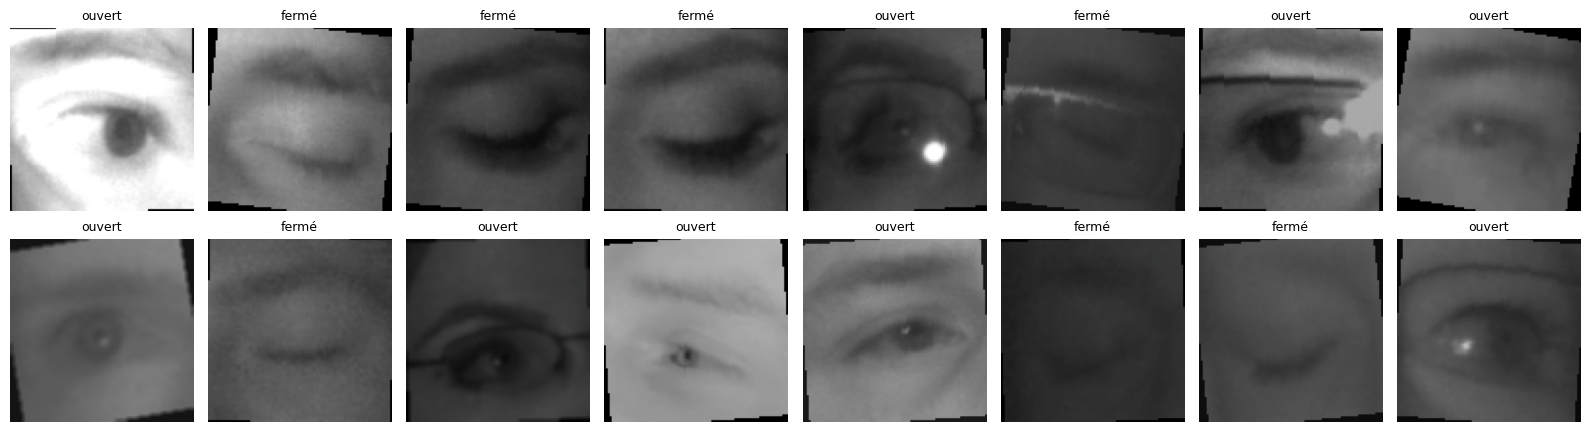

In [6]:
import matplotlib.pyplot as plt

def affiche(t):
    img = t.clone()
    for k in range(3):
        img[k] = img[k] * STD[k] + MOY[k]     # annule la normalisation
    return img.permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(16):
    ax = axes[i // 8, i % 8]
    ax.imshow(affiche(x[i]))
    ax.set_title("ouvert" if y[i] == 1 else "fermé", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/batch_augmente.png', dpi=150, bbox_inches='tight')
plt.show()